In [35]:
import numpy as np
import pandas as pd
RSEED = 50

In [36]:
# Drop Name and Ticket columns
titanic_data = pd.read_csv("train.csv")
titanic_data = titanic_data.drop(columns=["Name", "Ticket", "Cabin"])
titanic_data['Age'] = titanic_data['Age'].fillna(titanic_data['Age'].median())
titanic_data['Fare'] = titanic_data['Fare'].fillna(titanic_data['Fare'].median())
titanic_data['Embarked'] = titanic_data['Embarked'].fillna(titanic_data['Embarked'].mode()[0])
titanic_data.isnull().values.any()

np.False_

In [37]:
# Train Test Split 
from sklearn.model_selection import train_test_split
# 80/20 train-test split using RSEED
train_df, test_df = train_test_split(titanic_data, test_size=0.2, random_state=RSEED)

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")

Train shape: (712, 9)
Test shape: (179, 9)


In [38]:
from sklearn.model_selection import StratifiedKFold
# 5-fold cross-validation with shuffling and RSEED
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RSEED)
for fold, (train_idx, val_idx) in enumerate(skf.split(train_df, train_df['Survived']), 1):
    fold_train = train_df.iloc[train_idx]
    fold_val = train_df.iloc[val_idx]
    print(f"Fold {fold}: Train size = {len(fold_train)}, Val size = {len(fold_val)}")

Fold 1: Train size = 569, Val size = 143
Fold 2: Train size = 569, Val size = 143
Fold 3: Train size = 570, Val size = 142
Fold 4: Train size = 570, Val size = 142
Fold 5: Train size = 570, Val size = 142


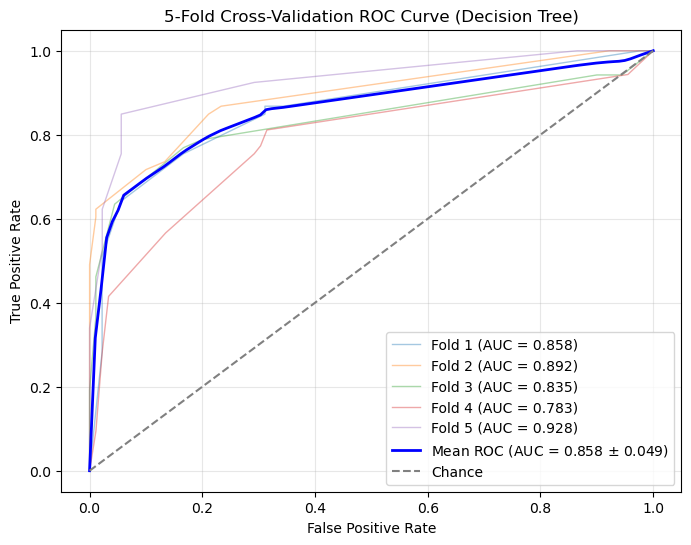

Average Accuracy across folds: 0.8202 +/- 0.0391
Average ROC AUC across folds:  0.8579 +/- 0.0495


In [39]:
#Decision Tree implementation
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, auc, accuracy_score

# Preprocess features within fold / training set for the Decision Tree
def preprocess(df, age_median=None, fare_median=None, embarked_mode=None):
    df = df.copy()
    # Drop identifier and columns with high missingness if present
    drop_cols = [c for c in ["PassengerId", "Name", "Ticket", "Cabin"] if c in df.columns]
    df = df.drop(columns=drop_cols)
    
    # Impute missing values
    if age_median is None:
        age_median = df["Age"].median()
    if fare_median is None:
        fare_median = df["Fare"].median()
    if embarked_mode is None:
        embarked_mode = df["Embarked"].mode()[0] if "Embarked" in df.columns and not df["Embarked"].dropna().empty else "S"
        
    df["Age"] = df["Age"].fillna(age_median)
    df["Fare"] = df["Fare"].fillna(fare_median)
    if "Embarked" in df.columns:
        df["Embarked"] = df["Embarked"].fillna(embarked_mode)
    
    # Encode categorical variables
    if "Sex" in df.columns:
        df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
    if "Embarked" in df.columns:
        df = pd.get_dummies(df, columns=["Embarked"], drop_first=True)
        
    return df, age_median, fare_median, embarked_mode

# Tracking metrics across folds
accuracies = []
aucs = []
tprs = []
mean_fpr = np.linspace(0, 1, 100)

plt.figure(figsize=(8, 6))

for fold, (train_idx, val_idx) in enumerate(skf.split(train_df, train_df["Survived"]), 1):
    # Split fold data
    raw_train_fold = train_df.iloc[train_idx]
    raw_val_fold = train_df.iloc[val_idx]
    
    # Preprocess fold data without data leakage
    train_fold, age_med, fare_med, emb_mode = preprocess(raw_train_fold)
    val_fold, _, _, _ = preprocess(raw_val_fold, age_med, fare_med, emb_mode)
    
    # Separate features and target
    X_tr = train_fold.drop(columns=["Survived"])
    y_tr = train_fold["Survived"]
    X_val = val_fold.drop(columns=["Survived"])
    y_val = val_fold["Survived"]
    
    # Align columns in case dummy categories differ across folds
    X_val = X_val.reindex(columns=X_tr.columns, fill_value=0)
    
    # Train Decision Tree
    dt = DecisionTreeClassifier(max_depth=4, random_state=RSEED)
    dt.fit(X_tr, y_tr)
    
    # Predictions and predicted probabilities
    y_pred = dt.predict(X_val)
    y_proba = dt.predict_proba(X_val)[:, 1]
    
    # Accuracy and ROC curve for this fold
    acc = accuracy_score(y_val, y_pred)
    accuracies.append(acc)
    
    fpr, tpr, _ = roc_curve(y_val, y_proba)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    
    # Interpolate TPR for averaging across folds
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
    
    plt.plot(fpr, tpr, lw=1, alpha=0.4, label=f"Fold {fold} (AUC = {roc_auc:.3f})")

# Calculate Mean ROC curve across all 5 folds
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)

# Plot Mean ROC curve and Chance line
plt.plot(mean_fpr, mean_tpr, color="blue", lw=2,
         label=f"Mean ROC (AUC = {mean_auc:.3f} $\pm$ {std_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", lw=1.5, color="grey", label="Chance")

plt.title("5-Fold Cross-Validation ROC Curve (Decision Tree)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

# Print averaged results
print(f"Average Accuracy across folds: {np.mean(accuracies):.4f} +/- {np.std(accuracies):.4f}")
print(f"Average ROC AUC across folds:  {mean_auc:.4f} +/- {std_auc:.4f}")